# Lab Problem 2 :  Polynomial Regression

Imports & Task 1 — Generate Data

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

# Set random seed for reproducibility
np.random.seed(42)

# 1. Generate 10 training data points (N = 10)
N = 10
x_train = np.linspace(0, 1, N).reshape(-1, 1)
noise = np.random.normal(loc=0.0, scale=0.02, size=N).reshape(-1, 1)
y_train = np.cos(2 * np.pi * x_train) + noise

# 2. Generate 100 clean test points for plotting the true curve
x_test = np.linspace(0, 1, 100).reshape(-1, 1)
y_test = np.cos(2 * np.pi * x_test)

print(f"x_train shape: {x_train.shape} | y_train shape: {y_train.shape}")
print(f"x_test shape:  {x_test.shape} | y_test shape:  {y_test.shape}")

x_train shape: (10, 1) | y_train shape: (10, 1)
x_test shape:  (100, 1) | y_test shape:  (100, 1)


Task 2 & Task 3 — Model Training, Feature Transformation & Evaluation

In [4]:
degrees = [0, 1, 3, 6, 9]

rmse_results = []
test_predictions = {}

for M in degrees:
    # 1. Transform x_train into polynomial features [1, x, x^2, ..., x^M]
    poly = PolynomialFeatures(degree=M)
    X_train_poly = poly.fit_transform(x_train)

    # 2. Initialize and train the Linear Regression model
    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    # 3. Predict on training data and compute Training RMSE
    y_train_pred = model.predict(X_train_poly)
    train_rmse = root_mean_squared_error(y_train, y_train_pred)
    rmse_results.append({"Polynomial Degree (M)": M, "Training RMSE": train_rmse})

    # 4. Transform x_test using the SAME PolynomialFeatures object and predict
    X_test_poly = poly.transform(x_test)
    test_predictions[M] = model.predict(X_test_poly)

print("All 5 polynomial models trained and evaluated successfully!")

All 5 polynomial models trained and evaluated successfully!


Deliverable 1 — Training RMSE Table

In [5]:
# Create and display the formatted RMSE Table
rmse_df = pd.DataFrame(rmse_results)
print(rmse_df.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

 Polynomial Degree (M)  Training RMSE
                     0       0.732959
                     1       0.732959
                     3       0.240305
                     6       0.007659
                     9       0.000000


Deliverable 2 — Model Fit Plot

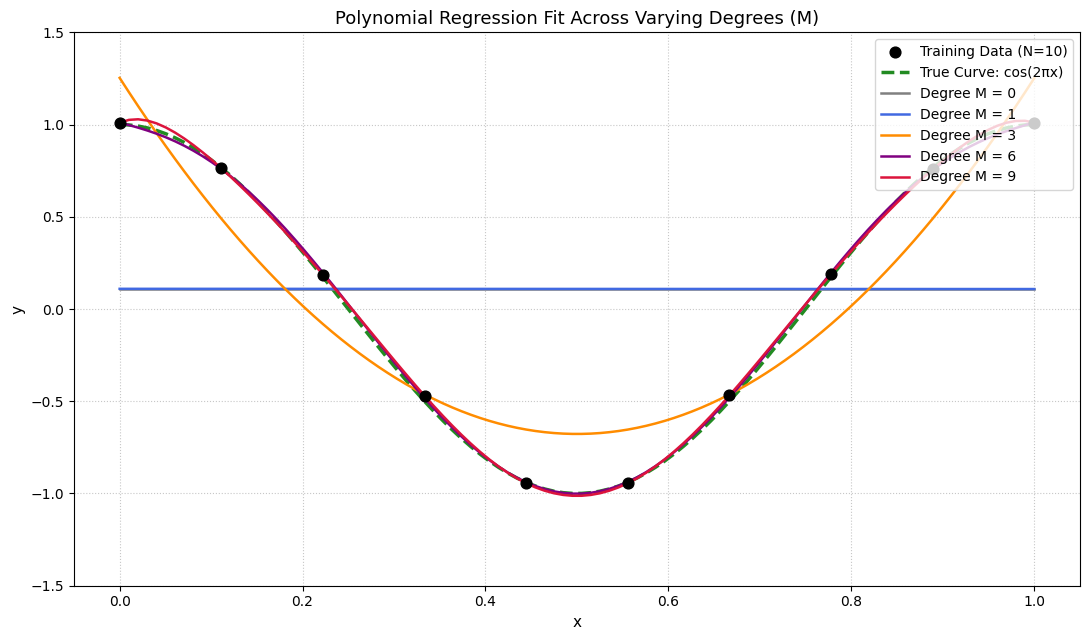

In [6]:
plt.figure(figsize=(11, 6.5))

# i. Plot the 10 noisy training data points
plt.scatter(x_train, y_train, color='black', s=60, zorder=5, label='Training Data (N=10)')

# ii. Plot the true underlying Cosine curve
plt.plot(x_test, y_test, color='forestgreen', linestyle='--', linewidth=2.5, label='True Curve: cos(2πx)')

# iii–vii. Plot predictions for M = [0, 1, 3, 6, 9]
colors = ['gray', 'royalblue', 'darkorange', 'purple', 'crimson']
for M, color in zip(degrees, colors):
    plt.plot(
        x_test,
        test_predictions[M],
        color=color,
        linewidth=1.8,
        label=f'Degree M = {M}'
    )

plt.title("Polynomial Regression Fit Across Varying Degrees (M)", fontsize=13)
plt.xlabel("x", fontsize=11)
plt.ylabel("y", fontsize=11)
plt.ylim(-1.5, 1.5)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()